In [1]:
# Import all the Libraries (Code Snippet from Lecture 4)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sqlite3
from pathlib import Path
from IPython.display import display
import re
%matplotlib inline
from matplotlib.collections import LineCollection
plt.style.use('seaborn-v0_8-whitegrid')

# 2.1 Parameters

In [2]:
# Parameters
ticker = "AAPL"  # Stock ticker to analyze
start_date = "2024-01-01"  # Analysis start date
end_date = "2024-12-31"  # Analysis end date

In [3]:
# Parameters
ticker = "IBM"
start_date = "2024-06-01"
end_date = "2024-11-30"


# 2.2 Load Data

In [4]:
# Load data with SQL
db_path = "data.db"
with sqlite3.connect(db_path) as conn:
    query = """
    SELECT * FROM ohlc_hw_cleaned
    WHERE ticker = ? AND ts BETWEEN ? AND ? AND adj_close <= close * 1.5
    ORDER BY ts
    """
    df_stock = pd.read_sql_query(query, conn, params=(ticker, start_date, end_date))

N = len(df_stock)

In [5]:
# 2. Validate input and check for insufficient history 
MIN_REQUIRED_ROWS = 50  # There are 50 days required for 50 day moving avg

if N < MIN_REQUIRED_ROWS:
    print(f"Validation failed: Calculating returns requires at least {MIN_REQUIRED_ROWS} price observations.")
else:
    # Get actual first and last observation dates
    actual_start = df_stock['ts'].min()
    actual_end = df_stock['ts'].max()
    
    # Display the summary date range and trading days
    print(f"{ticker} from {actual_start} to {actual_end}: {N} trading days")
    if actual_start != start_date or actual_end != end_date:
        print(f"(Note: Requested range was {start_date} to {end_date})")
        # These slightly differ but I think enough information is encaptulated. 
    
    # 3. Display first and last few rows
    print("\n--- First Few Rows ---")
    display(df_stock.head(3))
    
    print("\n--- Last Few Rows ---")
    display(df_stock.tail(3))

IBM from 2024-06-03 00:00:00 to 2024-11-29 00:00:00: 126 trading days
(Note: Requested range was 2024-06-01 to 2024-11-30)

--- First Few Rows ---


,ts,open,high,low,close,adj_close,volume,ticker,prev_close,return,return_outlier_flag,impossible_bound_flag,invalid_price_flag,ohlc_inconsistent_flag,zero_volume_flag,quarantine_status,outlier_status,evidence_note
0,2024-06-03 00:00:00,166.54,166.78,163.53,165.28,162.57,2776100,IBM,166.85,-0.009410,0,0,0,0,0,normal,normal,
1,2024-06-04 00:00:00,164.60,166.40,163.88,165.81,163.09,2594203,IBM,165.28,0.003207,0,0,0,0,0,normal,normal,
2,2024-06-05 00:00:00,166.41,167.79,165.78,167.38,164.63,3049400,IBM,165.81,0.009469,0,0,0,0,0,normal,normal,



--- Last Few Rows ---


,ts,open,high,low,close,adj_close,volume,ticker,prev_close,return,return_outlier_flag,impossible_bound_flag,invalid_price_flag,ohlc_inconsistent_flag,zero_volume_flag,quarantine_status,outlier_status,evidence_note
123,2024-11-26 00:00:00,226.73,228.98,225.51,228.83,228.83,4449543,IBM,226.13,0.011940,0,0,0,0,0,normal,normal,
124,2024-11-27 00:00:00,228.83,229.19,224.27,226.92,226.92,2995121,IBM,228.83,-0.008347,0,0,0,0,0,normal,normal,
125,2024-11-29 00:00:00,227.75,230.36,227.19,227.41,227.41,2640300,IBM,226.92,0.002159,0,0,0,0,0,normal,normal,


# 2.3  Calculate Risk Metrics

In [6]:
# Function to calculate daily returns
def calculate_returns(prices):
    """Calculate daily log returns"""
    return np.log(prices / prices.shift(1))
    
# Rolling volatility function over a 20 day window
def calculate_volatility(returns, window=20):
    """Calculate annualized rolling volatility"""
    return returns.rolling(window).std() * np.sqrt(252)

# Drawdown and Maximum Drawdown: 
def calculate_max_drawdown(prices):
    """Return per-date drawdown from the running price peak."""
    cum_max = prices.cummax()
    return (prices - cum_max) / cum_max

# Sharpe Ratio
def calculate_sharpe_ratio(returns, risk_free_rate=0.02):
    """Calculate annualized Sharpe ratio"""
    return (returns.mean() * 252 - risk_free_rate) / (returns.std() * np.sqrt(252))

In [7]:
# Apply functions to AAPL stock
df_stock['return'] = calculate_returns(df_stock['adj_close'])
df_stock['volatility_20d'] = calculate_volatility(df_stock['return'], window=20)
df_stock['drawdown'] = calculate_max_drawdown(df_stock['adj_close'])

# Calculate the Statistics (Sharpe and Max dropdown)
log_returns = df_stock['return'].dropna()
sharpe = calculate_sharpe_ratio(log_returns)
max_dd = df_stock['drawdown'].min()
latest_vol = df_stock['volatility_20d'].iloc[-1] if not df_stock['volatility_20d'].empty else np.nan

# Return NaN/display N/A for zero volatility or insufficient returns.
sharpe_str = f"{sharpe:.4f}" if not pd.isna(sharpe) else "N/A"
max_dd_str = f"{max_dd:.2%}" if not pd.isna(max_dd) else "N/A"
latest_vol_str = f"{latest_vol:.2%}" if not pd.isna(latest_vol) and latest_vol > 0 else "N/A"

# Display summary report
print(f"==========================================")
print(f" Performance Summary for {ticker}")
print(f"==========================================")
print(f"Annualized Sharpe Ratio (Rf = 2%): {sharpe_str}")
print(f"Maximum Drawdown:                  {max_dd_str}")
print(f"Latest 20-Day Annualized Volatility: {latest_vol_str}")
print("==========================================\n")

# Display calculations
print("--- Calculations with Volatility and Drawdown Statistics ---")
display(df_stock[['ts', 'adj_close', 'return', 'volatility_20d', 'drawdown']].tail(10))

 Performance Summary for IBM
Annualized Sharpe Ratio (Rf = 2%): 3.1492
Maximum Drawdown:                  -12.90%
Latest 20-Day Annualized Volatility: 21.21%

--- Calculations with Volatility and Drawdown Statistics ---


,ts,adj_close,return,volatility_20d,drawdown
116,2024-11-15 00:00:00,204.99,-0.019325,0.285676,-0.121798
117,2024-11-18 00:00:00,208.09,0.015009,0.294926,-0.108517
118,2024-11-19 00:00:00,210.25,0.010327,0.298959,-0.099263
119,2024-11-20 00:00:00,214.60,0.020479,0.311255,-0.080627
120,2024-11-21 00:00:00,222.40,0.035702,0.251189,-0.047211
121,2024-11-22 00:00:00,222.97,0.002560,0.241515,-0.044769
122,2024-11-25 00:00:00,226.13,0.014073,0.241623,-0.031231
123,2024-11-26 00:00:00,228.83,0.011869,0.236457,-0.019664
124,2024-11-27 00:00:00,226.92,-0.008382,0.212190,-0.027847
125,2024-11-29 00:00:00,227.41,0.002157,0.212125,-0.025748


# 2.4 Visualization

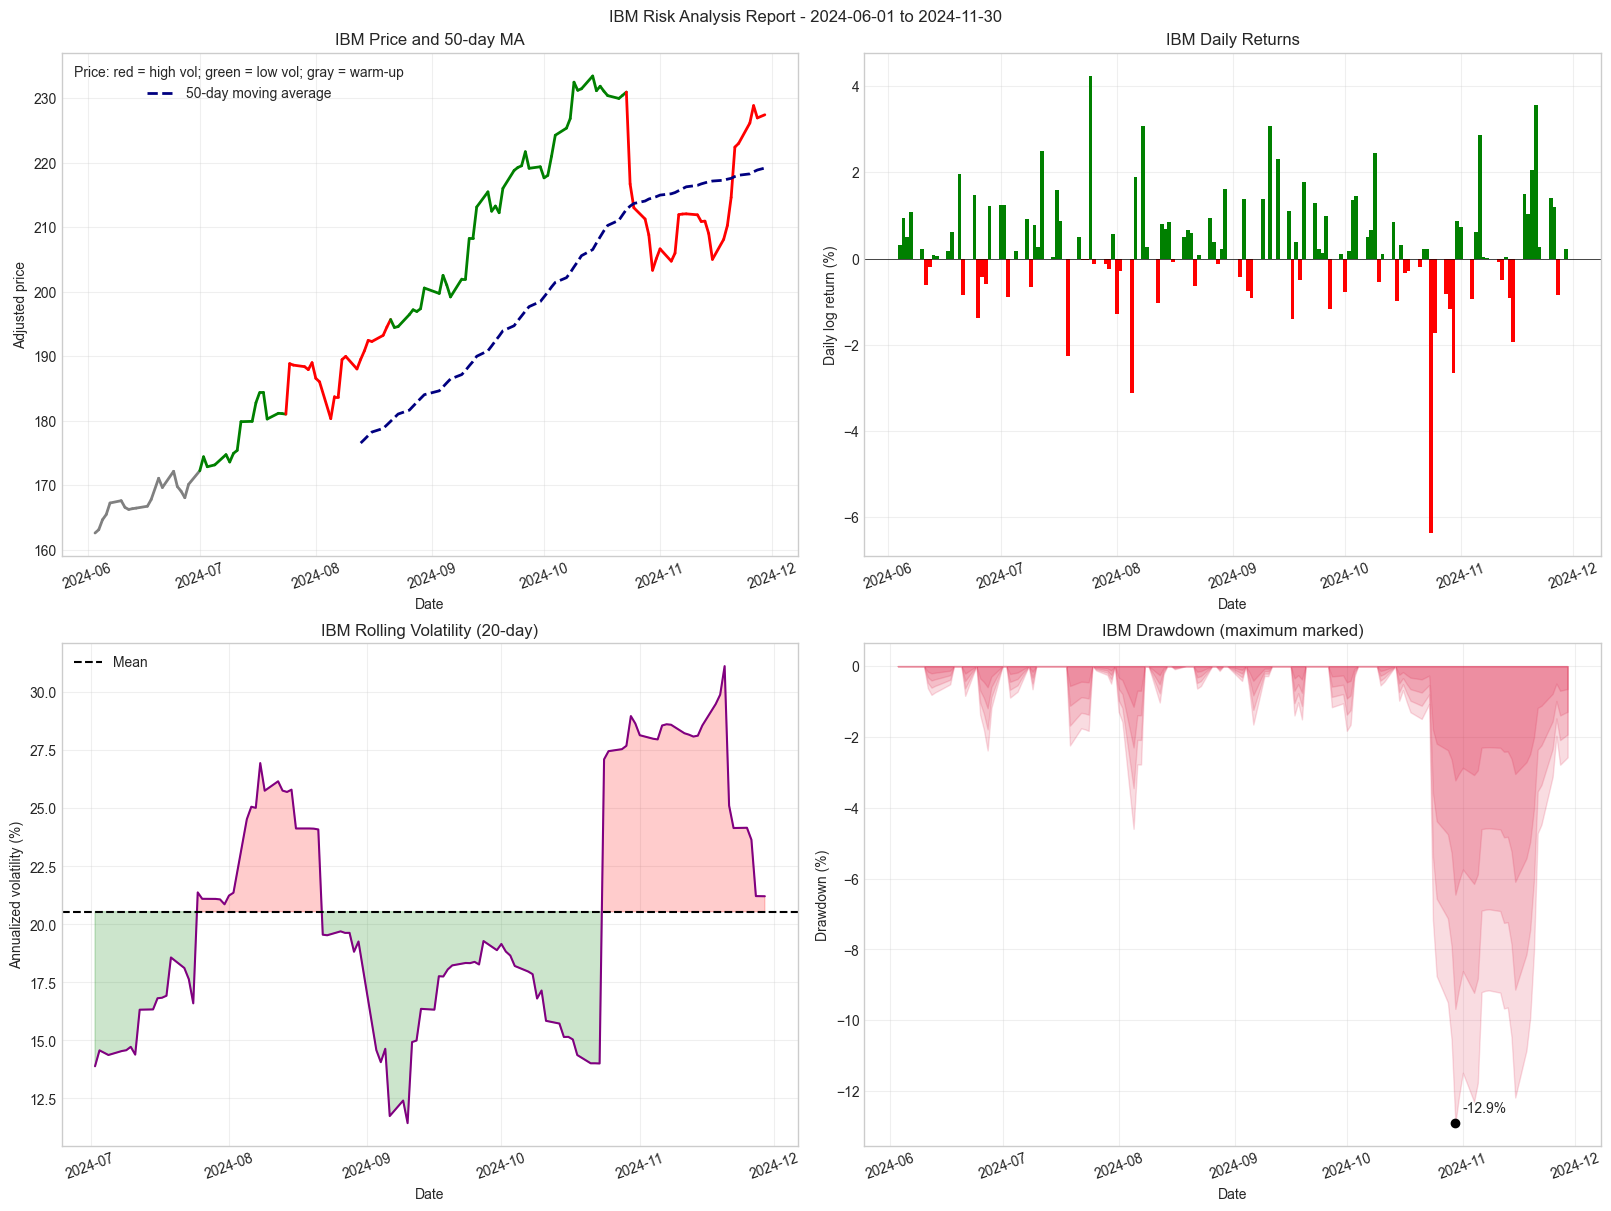

In [8]:
# 1. Ensure dataframe is sorted chronologically and set up DatetimeIndex
df = df_stock.sort_values('ts').copy()
if 'ts' in df.columns and not isinstance(df.index, pd.DatetimeIndex):
    df['ts'] = pd.to_datetime(df['ts'])
    df.set_index('ts', inplace=True)

# 2. Calculate moving average
df['sma_50'] = df['adj_close'].rolling(window=50).mean()
vol_window = 20
mean_volatility = df['volatility_20d'].mean()

# 3. Create 2x2 Subplot Grid
fig, axes = plt.subplots(2, 2, figsize=(16, 12), layout='constrained')
fig.suptitle(f'{ticker} Risk Analysis Report - {start_date} to {end_date}')

# TOP LEFT: Price Chart
# Color the line by volatility (high vol = red, low vol = green)
for i in range(1, len(df)):
    v_val = df['volatility_20d'].iloc[i]
    if pd.isna(v_val):
        color = 'gray'
    elif v_val <= mean_volatility:
        color = 'green'
    else:
        color = 'red'
    axes[0, 0].plot(
        df.index[i - 1 : i + 1],
        df['adj_close'].iloc[i - 1 : i + 1],
        color=color,
        linewidth=2.0,
        zorder=2
    )

# Plot 50-day moving average
axes[0, 0].plot(
    df.index,
    df['sma_50'],
    color='navy',
    linestyle='--',
    linewidth=2.0,
    label='50-day moving average',
    zorder=3
)
axes[0, 0].set(title=f'{ticker} Price and 50-day MA', ylabel='Adjusted price')
axes[0, 0].legend(
    title='Price: red = high vol; green = low vol; gray = warm-up',
    loc='upper left'
)

# TOP RIGHT: Daily Returns
# Bar chart, green (positive), red (negative)
axes[0, 1].bar(
    df.index,
    df['return'] * 100,
    width=1,
    color=np.where(df['return'].ge(0), 'green', 'red')
)
axes[0, 1].set(title=f'{ticker} Daily Returns', ylabel='Daily log return (%)')
axes[0, 1].axhline(0, color='black', linewidth=0.5) # Horizontal Line at 0

# BOTTOM LEFT: Rolling Volatility
vol_pct = df['volatility_20d'] * 100
mean_vol_pct = mean_volatility * 100
axes[1, 0].plot(df.index, vol_pct, color='purple')
# Horizontal line at mean volatility
axes[1, 0].axhline(mean_vol_pct, color='black', linestyle='--', label='Mean')

# Shade in regions (high/mean vol as red/green)
for condition, color in [
    (df['volatility_20d'] > mean_volatility, 'red'),
    (df['volatility_20d'] <= mean_volatility, 'green')
]:
    axes[1, 0].fill_between(
        df.index,
        vol_pct,
        mean_vol_pct,
        where=condition,
        color=color,
        alpha=0.2,
        interpolate=True
    )
axes[1, 0].set(
    title=f'{ticker} Rolling Volatility ({vol_window}-day)',
    ylabel='Annualized volatility (%)'
)
axes[1, 0].legend()

# BOTTOM RIGHT: Drawdown
# Area chard per date drawdown
drawdown_pct = df['drawdown'] * 100
for fraction in [1.0, 0.75, 0.5, 0.25]:
    # Fill below 0
    axes[1, 1].fill_between(
        df.index, drawdown_pct * fraction, 0, color='crimson', alpha=0.15
    )

if not drawdown_pct.empty and drawdown_pct.min() < 0:
    worst_date = drawdown_pct.idxmin()
    worst_val = drawdown_pct.loc[worst_date]
    axes[1, 1].scatter([worst_date], [worst_val], color='black', zorder=3)
    # Mark Maximum drop down (min val cause negative)
    axes[1, 1].annotate(
        f'{worst_val:.1f}%',
        (worst_date, worst_val),
        xytext=(5, 8),
        textcoords='offset points'
    )

axes[1, 1].set(
    title=f'{ticker} Drawdown (maximum marked)',
    ylabel='Drawdown (%)'
)

# Global grid and axis styling for all subplots
for ax in axes.flat:
    ax.set_xlabel('Date')
    ax.grid(True, alpha=0.3)
    ax.tick_params(axis='x', labelrotation=20)

plt.show()

# 2.5 Summary Statistics Table

In [9]:
# 2.5 Summary Statistics Table
def generate_summary_table(df_stock: pd.DataFrame, risk_free_rate: float = 0.02) -> pd.DataFrame:
    """Create Summary Statistics table to display total return, annualized return, 
    annualized volatility, sharpe ratio... etc."""
    prices = df_stock['adj_close'].dropna()
    n = len(log_returns)

    # Compute Total Return
    total_ret = (prices.iloc[-1] / prices.iloc[0]) - 1.0
    total_ret_str = f"{total_ret:+.2%}"

    # Compute Annualized Return
    ann_ret = np.exp(log_returns.sum() * 252.0 / n) - 1.0
    ann_ret_str = f"{ann_ret:+.2%}"

    # Annualized Volatility: std(log_returns) * sqrt(252)
    ann_vol = log_returns.std(ddof=1) * np.sqrt(252.0)
    ann_vol_str = f"{ann_vol:.2%}"
    
    # Best and Worst Day
    best_day = log_returns.max()
    worst_day = log_returns.min()
    best_day_str = f"{best_day:+.2%}"
    worst_day_str = f"{worst_day:+.2%}"

    # Positive Days, Average Up Day, Average Down Day
    up_days = log_returns[log_returns > 0]
    down_days = log_returns[log_returns < 0]
    # positive days
    pos_days_pct = len(up_days) / n
    pos_days_str = f"{pos_days_pct:.1%}"
    # average up/down day
    avg_up_str = f"{up_days.mean():+.2%}" if len(up_days) > 0 else "N/A"
    avg_down_str = f"{down_days.mean():+.2%}" if len(down_days) > 0 else "N/A"

    summary_rows = [
        ("Total Return", total_ret_str),
        ("Annualized Return", ann_ret_str),
        ("Annualized Volatility", ann_vol_str),
        ("Sharpe Ratio", sharpe_str),
        ("Maximum Drawdown", max_dd_str),
        ("Best Day", best_day_str),
        ("Worst Day", worst_day_str),
        ("Positive Days", pos_days_str),
        ("Average Up Day", avg_up_str),
        ("Average Down Day", avg_down_str),
    ] 
    return pd.DataFrame(summary_rows, columns=["Metric", "Value"])

# Generate the summary table
summary_df = generate_summary_table(df_stock)

# Also display as a clean pandas DataFrame
display(summary_df)

# Note: the annualized return is larger than the 
# total return because the period for total return is less than a year

,Metric,Value
0,Total Return,+39.88%
1,Annualized Return,+96.73%
2,Annualized Volatility,20.85%
3,Sharpe Ratio,3.1492
4,Maximum Drawdown,-12.90%
5,Best Day,+4.24%
6,Worst Day,-6.37%
7,Positive Days,61.6%
8,Average Up Day,+0.97%
9,Average Down Day,-0.94%


In [10]:
import scrapbook as sb

# Calculate any outputs required in the portfolio csv
prices = df_stock["adj_close"].dropna()
returns = df_stock["return"].dropna()
avg_daily_ret_val = float(returns.mean())
avg_vol_val = float(df_stock["volatility_20d"].mean())
total_ret = (prices.iloc[-1] / prices.iloc[0]) - 1.0
total_ret_str = f"{total_ret:+.2%}"

# Glue outputs into the notebook for Scrapbook
sb.glue("ticker", ticker)
sb.glue("avg_daily_return", avg_daily_ret_val)
sb.glue("avg_volatility", avg_vol_val)
sb.glue("max_drawdown", max_dd)
sb.glue("sharpe_ratio", sharpe)
sb.glue("total_return", total_ret)